Veri Seti Boyutu: (32833, 23)


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052



Temizlenmiş Veri Boyutu: (28352, 24)
Popüler / Popüler Değil Dağılımı:
 is_popular
0    21935
1     6417
Name: count, dtype: int64


/tmp/ipykernel_897/3584711320.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clean, x='playlist_genre', y='track_popularity', palette='viridis', errorbar=None)


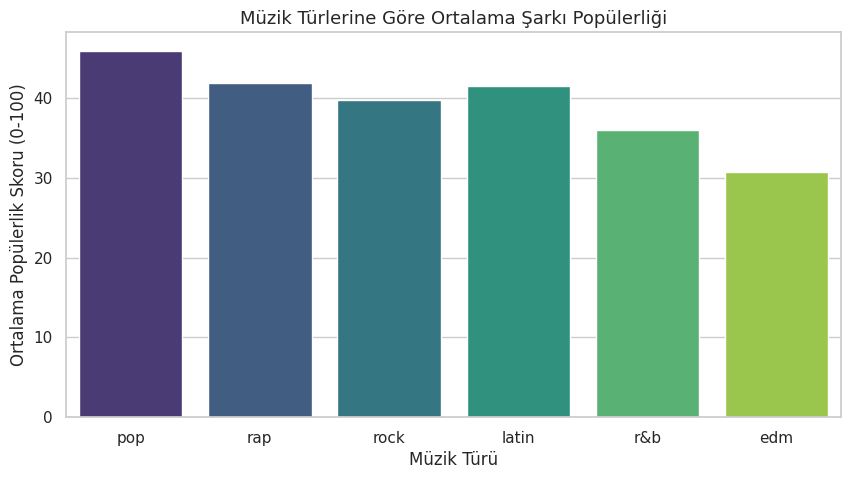

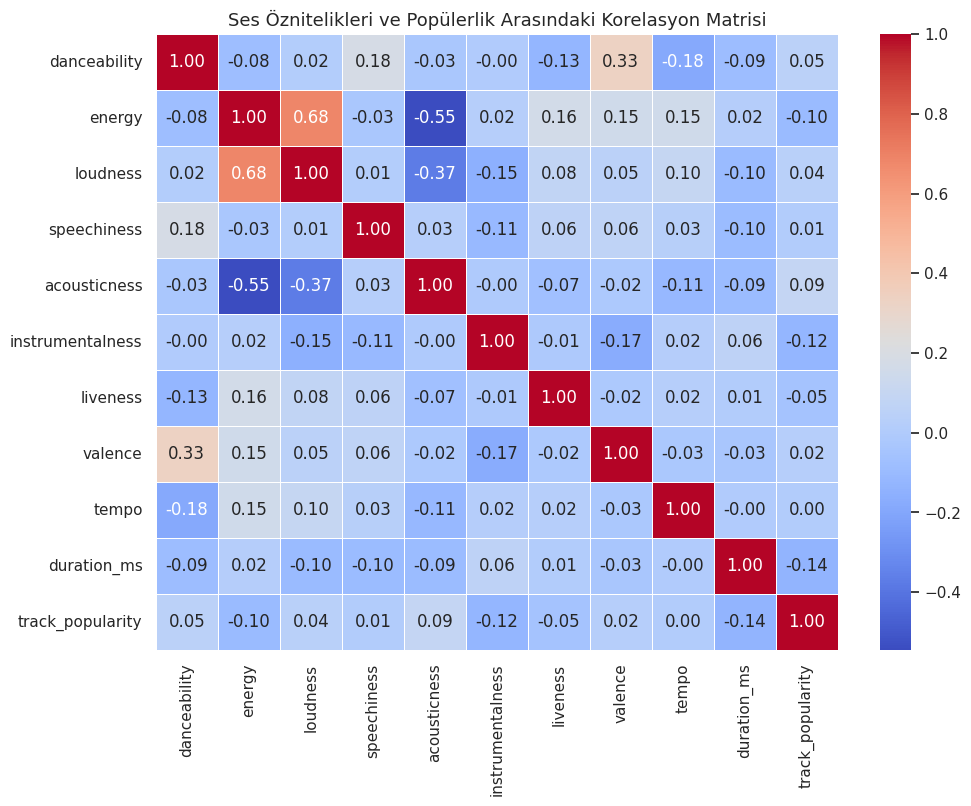


Lojistik Regresyon Doğruluk (Accuracy) Oranı: %77.36
Random Forest Doğruluk (Accuracy) Oranı: %77.18


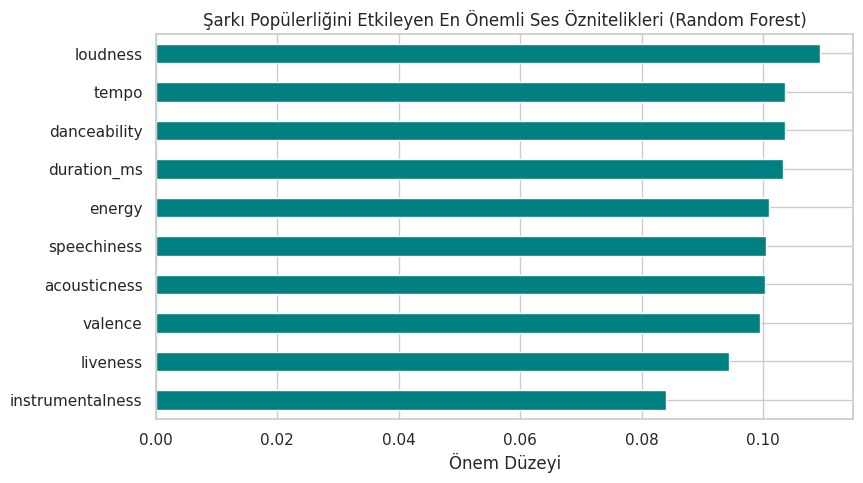

In [1]:
# 1. KÜTÜPHANELERİN YÜKLENMESİ
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Görsel tema ayarı
sns.set_theme(style="whitegrid")

# 2. VERİ SETİNİN YÜKLENMESİ (Açık kaynak Spotify Tracks veri seti)
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv"
df = pd.read_csv(url)

print("Veri Seti Boyutu:", df.shape)
display(df.head())

# 3. VERİ ÖN İŞLEME VE TEMİZLEME
# Eksik verilerin temizlenmesi ve tekrar eden şarkıların çıkarılması
df_clean = df.dropna().drop_duplicates(subset=['track_id']).copy()

# Hedef Değişken Oluşturma: Popülerlik skoru 60 ve üzeri ise Popüler (1), değilse (0)
df_clean['is_popular'] = (df_clean['track_popularity'] >= 60).astype(int)

# Analizde kullanılacak ses (audio) öznitelikleri
features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']

print("\nTemizlenmiş Veri Boyutu:", df_clean.shape)
print("Popüler / Popüler Değil Dağılımı:\n", df_clean['is_popular'].value_counts())

# 4. KEŞİFSEL VERİ ANALİZİ (EDA) VE GÖRSELLEŞTİRME
# Grafik 1: Müzik Türlerine Göre Ortalama Popülerlik
plt.figure(figsize=(10, 5))
sns.barplot(data=df_clean, x='playlist_genre', y='track_popularity', palette='viridis', errorbar=None)
plt.title('Müzik Türlerine Göre Ortalama Şarkı Popülerliği', fontsize=13)
plt.xlabel('Müzik Türü')
plt.ylabel('Ortalama Popülerlik Skoru (0-100)')
plt.show()

# Grafik 2: Ses Öznitelikleri Korelasyon Matrisi
plt.figure(figsize=(11, 8))
corr = df_clean[features + ['track_popularity']].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Ses Öznitelikleri ve Popülerlik Arasındaki Korelasyon Matrisi', fontsize=13)
plt.show()

# 5. MAKİNE ÖĞRENMESİ MODELLEMESİ (VİZE PROTOTİP AŞAMASI)
X = df_clean[features]
y = df_clean['is_popular']

# Eğitim (%80) ve Test (%20) ayrımı
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Ölçeklendirme (Standardizasyon)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model 1: Lojistik Regresyon
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)
print(f"\nLojistik Regresyon Doğruluk (Accuracy) Oranı: %{accuracy_score(y_test, lr_pred)*100:.2f}")

# Model 2: Random Forest Sınıflandırıcı
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print(f"Random Forest Doğruluk (Accuracy) Oranı: %{accuracy_score(y_test, rf_pred)*100:.2f}")

# Grafik 3: Random Forest Öznitelik Önem Düzeyleri (Feature Importance)
importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=True)
plt.figure(figsize=(9, 5))
importances.plot(kind='barh', color='teal')
plt.title('Şarkı Popülerliğini Etkileyen En Önemli Ses Öznitelikleri (Random Forest)', fontsize=12)
plt.xlabel('Önem Düzeyi')
plt.show()